In [30]:
import sys
sys.path.append("..")

import copy
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
from sklearn.model_selection import KFold
import os
from src.dcsr import DCSRRegressor, Node
from joblib import dump
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

In [31]:
# DCSR PARAMETERS

LAMBDA = 1e9

POPULATION_SIZE = 500
GENERATIONS = 50

TOURNAMENT_SIZE = 20

MAX_DEPTH = 5
MIN_DEPTH = 2

P_CROSSOVER = 0.70
P_MUTATION = 0.30

CONST_MIN = -10.0
CONST_MAX = 10.0

RANDOM_STATE = 42

print("DCSR parameters")
print("-" * 50)
print(f"Lambda              : {LAMBDA:.0e}")
print(f"Population size     : {POPULATION_SIZE}")
print(f"Generations         : {GENERATIONS}")
print(f"Tournament size     : {TOURNAMENT_SIZE}")
print(f"Maximum tree depth  : {MAX_DEPTH}")
print(f"Crossover probability: {P_CROSSOVER}")
print(f"Mutation probability : {P_MUTATION}")

DCSR parameters
--------------------------------------------------
Lambda              : 1e+09
Population size     : 500
Generations         : 50
Tournament size     : 20
Maximum tree depth  : 5
Crossover probability: 0.7
Mutation probability : 0.3


In [32]:
# LOAD DATASET
S_old_path = "../data/processed/S_old_temporal_train.csv"
S_new_path = "../data/processed/S_new_temporal_test.csv"


train_df = pd.read_csv(S_old_path)
test_df = pd.read_csv(S_new_path)

print("Training samples:", train_df.shape[0])
print("Testing samples:", test_df.shape[0])


Training samples: 1983
Testing samples: 4002


In [33]:
# FEATURE DEFINITIONS

NUMERIC_COLUMNS = [
    "engine_size",
    "cylinders",
    # "engine_per_cylinder",
    # "engine_x_cylinders",
    # "engine_size_sq",
    # "cylinders_sq"
]

TARGET = "co2"

FEATURE_COLUMNS = (
    NUMERIC_COLUMNS
)

In [34]:
# CREATE TRAINING AND TESTING DATA

X_train = train_df[NUMERIC_COLUMNS].copy()
y_train = train_df[TARGET].copy()

X_test = test_df[NUMERIC_COLUMNS].copy()
y_test = test_df[TARGET].copy()

print("\nTraining X shape:", X_train.shape)
print("Testing X shape :", X_test.shape)


Training X shape: (1983, 2)
Testing X shape : (4002, 2)


In [35]:
# HANDLE MISSING / INFINITE VALUES

X_train = X_train.replace(
    [np.inf, -np.inf],
    np.nan
)

X_test = X_test.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fit imputation values only on training data
train_medians = X_train.median()

X_train = X_train.fillna(
    train_medians
)

X_test = X_test.fillna(
    train_medians
)

print("\nEncoded training shape:", X_train.shape)
print("Encoded testing shape :", X_test.shape)

print(
    "Training missing values:",
    X_train.isna().sum().sum()
)

print(
    "Testing missing values:",
    X_test.isna().sum().sum()
)


Encoded training shape: (1983, 2)
Encoded testing shape : (4002, 2)
Training missing values: 0
Testing missing values: 0


In [36]:
# CONVERT TO NUMPY

X_train_np = X_train.to_numpy(
    dtype=float
)

X_test_np = X_test.to_numpy(
    dtype=float
)

y_train_np = y_train.to_numpy(
    dtype=float
)

y_test_np = y_test.to_numpy(
    dtype=float
)

In [37]:
# FIND ENGINE SIZE INDEX

feature_names = list(
    X_train.columns
)

engine_size_col_idx = (
    feature_names.index("engine_size")
)

print(
    "\nengine_size index:",
    engine_size_col_idx
)

print(
    "Confirmed feature:",
    feature_names[
        engine_size_col_idx
    ]
)




engine_size index: 0
Confirmed feature: engine_size


In [38]:
# # PROTECTED MATHEMATICAL OPERATORS

# EPS = 1e-10


# def protected_div(a, b):
#     """
#     Protected division.
#     """
#     b_safe = np.where(
#         np.abs(b) < EPS,
#         np.where(b >= 0, EPS, -EPS),
#         b
#     )

#     return a / b_safe


# def protected_log(x):
#     """
#     Protected natural logarithm.
#     """
#     return np.log(np.maximum(np.abs(x), EPS))


# def protected_exp(x):
#     """
#     Protected exponential to prevent overflow.
#     """
#     return np.exp(np.clip(x, -50, 50))

In [39]:
# # SYMBOLIC TREE NODE

# class Node:

#     def __init__(
#         self,
#         node_type,
#         value=None,
#         left=None,
#         right=None
#     ):
#         self.node_type = node_type
#         self.value = value
#         self.left = left
#         self.right = right

#     def clone(self):
#         return copy.deepcopy(self)

#     # --------------------------------------------------------
#     # Evaluate equation
#     # --------------------------------------------------------

#     def evaluate(self, X):

#         if self.node_type == "constant":
#             return np.full(
#                 X.shape[0],
#                 self.value,
#                 dtype=float
#             )

#         if self.node_type == "variable":
#             return X[:, self.value]

#         if self.node_type == "add":

#             return (
#                 self.left.evaluate(X)
#                 +
#                 self.right.evaluate(X)
#             )

#         if self.node_type == "sub":

#             return (
#                 self.left.evaluate(X)
#                 -
#                 self.right.evaluate(X)
#             )

#         if self.node_type == "mul":

#             return (
#                 self.left.evaluate(X)
#                 *
#                 self.right.evaluate(X)
#             )

#         if self.node_type == "div":

#             return protected_div(
#                 self.left.evaluate(X),
#                 self.right.evaluate(X)
#             )

#         if self.node_type == "exp":

#             return protected_exp(
#                 self.left.evaluate(X)
#             )

#         if self.node_type == "log":

#             return protected_log(
#                 self.left.evaluate(X)
#             )

#         raise ValueError(
#             f"Unknown node type: {self.node_type}"
#         )

#     # --------------------------------------------------------
#     # Exact symbolic derivative
#     # --------------------------------------------------------

#     def derivative(self, X, variable_index):

#         # Constant derivative = 0
#         if self.node_type == "constant":

#             return np.zeros(
#                 X.shape[0],
#                 dtype=float
#             )

#         # Variable derivative
#         if self.node_type == "variable":

#             if self.value == variable_index:

#                 return np.ones(
#                     X.shape[0],
#                     dtype=float
#                 )

#             return np.zeros(
#                 X.shape[0],
#                 dtype=float
#             )

#         # ----------------------------------------------------
#         # Addition
#         # d(a+b) = da + db
#         # ----------------------------------------------------

#         if self.node_type == "add":

#             return (
#                 self.left.derivative(
#                     X,
#                     variable_index
#                 )
#                 +
#                 self.right.derivative(
#                     X,
#                     variable_index
#                 )
#             )

#         # ----------------------------------------------------
#         # Subtraction
#         # d(a-b) = da - db
#         # ----------------------------------------------------

#         if self.node_type == "sub":

#             return (
#                 self.left.derivative(
#                     X,
#                     variable_index
#                 )
#                 -
#                 self.right.derivative(
#                     X,
#                     variable_index
#                 )
#             )

#         # ----------------------------------------------------
#         # Multiplication
#         #
#         # d(ab) = a db + b da
#         # ----------------------------------------------------

#         if self.node_type == "mul":

#             a = self.left.evaluate(X)
#             b = self.right.evaluate(X)

#             da = self.left.derivative(
#                 X,
#                 variable_index
#             )

#             db = self.right.derivative(
#                 X,
#                 variable_index
#             )

#             return (
#                 da * b
#                 +
#                 a * db
#             )

#         # ----------------------------------------------------
#         # Division
#         #
#         # d(a/b) = (da*b - a*db) / b²
#         # ----------------------------------------------------

#         if self.node_type == "div":

#             a = self.left.evaluate(X)
#             b = self.right.evaluate(X)

#             da = self.left.derivative(
#                 X,
#                 variable_index
#             )

#             db = self.right.derivative(
#                 X,
#                 variable_index
#             )

#             b_safe = np.where(
#                 np.abs(b) < EPS,
#                 np.where(
#                     b >= 0,
#                     EPS,
#                     -EPS
#                 ),
#                 b
#             )

#             return (
#                 da * b_safe
#                 -
#                 a * db
#             ) / (
#                 b_safe ** 2
#             )

#         # ----------------------------------------------------
#         # Exponential
#         #
#         # d(exp(a)) = exp(a) da
#         # ----------------------------------------------------

#         if self.node_type == "exp":

#             a = self.left.evaluate(X)

#             da = self.left.derivative(
#                 X,
#                 variable_index
#             )

#             return (
#                 protected_exp(a)
#                 *
#                 da
#             )

#         # ----------------------------------------------------
#         # Logarithm
#         #
#         # d(log(|a|)) = da/a
#         # ----------------------------------------------------

#         if self.node_type == "log":

#             a = self.left.evaluate(X)

#             da = self.left.derivative(
#                 X,
#                 variable_index
#             )

#             a_safe = np.where(
#                 np.abs(a) < EPS,
#                 np.where(
#                     a >= 0,
#                     EPS,
#                     -EPS
#                 ),
#                 a
#             )

#             return da / a_safe

#         raise ValueError(
#             f"Unknown node type: {self.node_type}"
#         )

#     # --------------------------------------------------------
#     # Number of nodes
#     # --------------------------------------------------------

#     def length(self):

#         if self.node_type in [
#             "constant",
#             "variable"
#         ]:
#             return 1

#         if self.node_type in [
#             "exp",
#             "log"
#         ]:

#             return (
#                 1
#                 +
#                 self.left.length()
#             )

#         return (
#             1
#             +
#             self.left.length()
#             +
#             self.right.length()
#         )

#     # --------------------------------------------------------
#     # Tree depth
#     # --------------------------------------------------------

#     def depth(self):

#         if self.node_type in [
#             "constant",
#             "variable"
#         ]:
#             return 1

#         if self.node_type in [
#             "exp",
#             "log"
#         ]:

#             return (
#                 1
#                 +
#                 self.left.depth()
#             )

#         return (
#             1
#             +
#             max(
#                 self.left.depth(),
#                 self.right.depth()
#             )
#         )

In [40]:
# # SYMBOLIC EQUATION STRING

# def tree_to_string(node, feature_names):

#     if node.node_type == "constant":

#         return f"{node.value:.4f}"

#     if node.node_type == "variable":

#         return feature_names[node.value]

#     if node.node_type == "add":

#         return (
#             "("
#             + tree_to_string(
#                 node.left,
#                 feature_names
#             )
#             + " + "
#             + tree_to_string(
#                 node.right,
#                 feature_names
#             )
#             + ")"
#         )

#     if node.node_type == "sub":

#         return (
#             "("
#             + tree_to_string(
#                 node.left,
#                 feature_names
#             )
#             + " - "
#             + tree_to_string(
#                 node.right,
#                 feature_names
#             )
#             + ")"
#         )

#     if node.node_type == "mul":

#         return (
#             "("
#             + tree_to_string(
#                 node.left,
#                 feature_names
#             )
#             + " * "
#             + tree_to_string(
#                 node.right,
#                 feature_names
#             )
#             + ")"
#         )

#     if node.node_type == "div":

#         return (
#             "("
#             + tree_to_string(
#                 node.left,
#                 feature_names
#             )
#             + " / "
#             + tree_to_string(
#                 node.right,
#                 feature_names
#             )
#             + ")"
#         )

#     if node.node_type == "exp":

#         return (
#             "exp("
#             + tree_to_string(
#                 node.left,
#                 feature_names
#             )
#             + ")"
#         )

#     if node.node_type == "log":

#         return (
#             "log("
#             + tree_to_string(
#                 node.left,
#                 feature_names
#             )
#             + ")"
#         )

#     raise ValueError(
#         f"Unknown node type: {node.node_type}"
#     )

In [41]:
# # RANDOM TREE GENERATION

# BINARY_OPERATORS = [
#     "add",
#     "sub",
#     "mul",
#     "div"
# ]

# UNARY_OPERATORS = [
#     "exp",
#     "log"
# ]


# def random_terminal(
#     n_features,
#     rng
# ):

#     # Randomly choose variable or constant
#     if rng.random() < 0.70:

#         return Node(
#             node_type="variable",
#             value=int(
#                 rng.integers(
#                     0,
#                     n_features
#                 )
#             )
#         )

#     return Node(
#         node_type="constant",
#         value=float(
#             rng.uniform(
#                 CONST_MIN,
#                 CONST_MAX
#             )
#         )
#     )


# def random_tree(
#     n_features,
#     depth,
#     rng
# ):

#     # Terminal condition
#     if depth >= MAX_DEPTH:

#         return random_terminal(
#             n_features,
#             rng
#         )

#     # Force terminal sometimes at shallow depth
#     if depth >= MIN_DEPTH and rng.random() < 0.30:

#         return random_terminal(
#             n_features,
#             rng
#         )

#     # Select operator
#     if rng.random() < 0.70:

#         operator = rng.choice(
#             BINARY_OPERATORS
#         )

#         left = random_tree(
#             n_features,
#             depth + 1,
#             rng
#         )

#         right = random_tree(
#             n_features,
#             depth + 1,
#             rng
#         )

#         return Node(
#             node_type=operator,
#             left=left,
#             right=right
#         )

#     else:

#         operator = rng.choice(
#             UNARY_OPERATORS
#         )

#         child = random_tree(
#             n_features,
#             depth + 1,
#             rng
#         )

#         return Node(
#             node_type=operator,
#             left=child
#         )

In [42]:
# # DCSR FITNESS

# def calculate_dcsr_fitness(
#     tree,
#     X,
#     y,
#     engine_idx,
#     lambda_penalty
# ):

#     try:

#         # ----------------------------------------------------
#         # Prediction
#         # ----------------------------------------------------

#         y_pred = tree.evaluate(X)

#         if not np.all(
#             np.isfinite(y_pred)
#         ):
#             return np.inf, np.inf, np.inf, None

#         # ----------------------------------------------------
#         # Data error
#         # ----------------------------------------------------

#         e_data = np.mean(
#             (y - y_pred) ** 2
#         )

#         # ----------------------------------------------------
#         # Exact symbolic derivative
#         # ----------------------------------------------------

#         derivative = tree.derivative(
#             X,
#             engine_idx
#         )

#         if not np.all(
#             np.isfinite(derivative)
#         ):
#             return np.inf, e_data, np.inf, None

#         # ----------------------------------------------------
#         # Physical violation
#         #
#         # df/d(engine_size) >= 0
#         # ----------------------------------------------------

#         violations = np.maximum(
#             0.0,
#             -derivative
#         )

#         # ----------------------------------------------------
#         # Proposal:
#         #
#         # E_phys =
#         # lambda/N * sum(max(0,-derivative))
#         # ----------------------------------------------------

#         e_phys = (
#             lambda_penalty
#             *
#             np.mean(violations)
#         )

#         # ----------------------------------------------------
#         # Final DCSR objective
#         # ----------------------------------------------------

#         dcsr_score = (
#             e_data
#             +
#             e_phys
#         )

#         return (
#             dcsr_score,
#             e_data,
#             e_phys,
#             derivative
#         )

#     except Exception:

#         return (
#             np.inf,
#             np.inf,
#             np.inf,
#             None
#         )

In [43]:
# # TOURNAMENT SELECTION

# def tournament_selection(
#     evaluated_population,
#     tournament_size,
#     rng
# ):

#     selected_indices = rng.integers(
#         0,
#         len(evaluated_population),
#         size=tournament_size
#     )

#     selected = [
#         evaluated_population[i]
#         for i in selected_indices
#     ]

#     winner = min(
#         selected,
#         key=lambda x: x["fitness"]
#     )

#     return winner["tree"].clone()

In [44]:
# # SUBTREE CROSSOVER

# def get_nodes(node):

#     nodes = [node]

#     if node.left is not None:

#         nodes.extend(
#             get_nodes(node.left)
#         )

#     if node.right is not None:

#         nodes.extend(
#             get_nodes(node.right)
#         )

#     return nodes


# def replace_node(
#     root,
#     target,
#     replacement
# ):

#     if root is target:

#         return replacement

#     if root.left is not None:

#         root.left = replace_node(
#             root.left,
#             target,
#             replacement
#         )

#     if root.right is not None:

#         root.right = replace_node(
#             root.right,
#             target,
#             replacement
#         )

#     return root


# def subtree_crossover(
#     parent1,
#     parent2,
#     rng
# ):

#     child = parent1.clone()
#     donor = parent2.clone()

#     child_nodes = get_nodes(child)
#     donor_nodes = get_nodes(donor)

#     target = rng.choice(
#         child_nodes
#     )

#     replacement = rng.choice(
#         donor_nodes
#     ).clone()

#     child = replace_node(
#         child,
#         target,
#         replacement
#     )

#     # Prevent excessive depth
#     if child.depth() > MAX_DEPTH + 2:

#         return parent1.clone()

#     return child

In [45]:
# # Subtree mutation

# def subtree_mutation(
#     tree,
#     n_features,
#     rng
# ):

#     mutated = tree.clone()

#     nodes = get_nodes(mutated)

#     target = rng.choice(
#         nodes
#     )

#     replacement = random_tree(
#         n_features=n_features,
#         depth=0,
#         rng=rng
#     )

#     mutated = replace_node(
#         mutated,
#         target,
#         replacement
#     )

#     if mutated.depth() > MAX_DEPTH + 2:

#         return tree.clone()

#     return mutated

In [46]:
# # POPULATION EVALUATION

# def evaluate_population(
#     population,
#     X,
#     y,
#     engine_idx,
#     lambda_penalty
# ):

#     evaluated = []

#     for tree in population:

#         (
#             fitness,
#             e_data,
#             e_phys,
#             derivative
#         ) = calculate_dcsr_fitness(
#             tree,
#             X,
#             y,
#             engine_idx,
#             lambda_penalty
#         )

#         evaluated.append(
#             {
#                 "tree": tree,
#                 "fitness": fitness,
#                 "e_data": e_data,
#                 "e_phys": e_phys,
#                 "derivative": derivative
#             }
#         )

#     evaluated.sort(
#         key=lambda x: x["fitness"]
#     )

#     return evaluated

In [47]:
# # DCSR EVOLUTIONARY SEARCH

# class DCSRRegressor:

#     def __init__(
#         self,
#         population_size=500,
#         generations=10,
#         tournament_size=20,
#         engine_col_idx=None,
#         lambda_penalty=1e9,
#         random_state=42
#     ):

#         self.population_size = population_size
#         self.generations = generations
#         self.tournament_size = tournament_size
#         self.engine_col_idx = engine_col_idx
#         self.lambda_penalty = lambda_penalty
#         self.random_state = random_state

#         self.best_tree_ = None
#         self.best_fitness_ = np.inf
#         self.best_e_data_ = np.inf
#         self.best_e_phys_ = np.inf
#         self.best_generation_ = None

#         self.history_ = []

#     # --------------------------------------------------------
#     # Fit
#     # --------------------------------------------------------

#     def fit(self, X, y):

#         X = np.asarray(
#             X,
#             dtype=float
#         )

#         y = np.asarray(
#             y,
#             dtype=float
#         )

#         if self.engine_col_idx is None:

#             raise ValueError(
#                 "engine_col_idx must be specified."
#             )

#         n_features = X.shape[1]

#         rng = np.random.default_rng(
#             self.random_state
#         )

#         # ----------------------------------------------------
#         # Initial population
#         # ----------------------------------------------------

#         population = [

#             random_tree(
#                 n_features=n_features,
#                 depth=0,
#                 rng=rng
#             )

#             for _ in range(
#                 self.population_size
#             )
#         ]

#         # ----------------------------------------------------
#         # Evolution
#         # ----------------------------------------------------

#         for generation in range(
#             self.generations
#         ):

#             start_generation = time.perf_counter()

#             evaluated = evaluate_population(
#                 population,
#                 X,
#                 y,
#                 self.engine_col_idx,
#                 self.lambda_penalty
#             )

#             generation_best = evaluated[0]

#             # ------------------------------------------------
#             # Store global best
#             # ------------------------------------------------

#             if (
#                 generation_best["fitness"]
#                 <
#                 self.best_fitness_
#             ):

#                 self.best_fitness_ = (
#                     generation_best["fitness"]
#                 )

#                 self.best_tree_ = (
#                     generation_best["tree"].clone()
#                 )

#                 self.best_e_data_ = (
#                     generation_best["e_data"]
#                 )

#                 self.best_e_phys_ = (
#                     generation_best["e_phys"]
#                 )

#                 self.best_generation_ = (
#                     generation
#                 )

#             generation_time = (
#                 time.perf_counter()
#                 - start_generation
#             )

#             self.history_.append(
#                 {
#                     "generation": generation,
#                     "best_fitness":
#                         generation_best["fitness"],
#                     "best_e_data":
#                         generation_best["e_data"],
#                     "best_e_phys":
#                         generation_best["e_phys"],
#                     "tree_length":
#                         generation_best["tree"].length(),
#                     "tree_depth":
#                         generation_best["tree"].depth(),
#                     "time_seconds":
#                         generation_time
#                 }
#             )

#             print(
#                 f"Generation "
#                 f"{generation + 1:3d}/"
#                 f"{self.generations} | "
#                 f"Fitness = "
#                 f"{generation_best['fitness']:.6e} | "
#                 f"MSE = "
#                 f"{generation_best['e_data']:.4f} | "
#                 f"Penalty = "
#                 f"{generation_best['e_phys']:.4e} | "
#                 f"Length = "
#                 f"{generation_best['tree'].length()}"
#             )

#             # ------------------------------------------------
#             # Elitism
#             # ------------------------------------------------

#             new_population = [
#                 evaluated[0]["tree"].clone()
#             ]

#             # ------------------------------------------------
#             # Create next generation
#             # ------------------------------------------------

#             while len(new_population) < self.population_size:

#                 parent1 = tournament_selection(
#                     evaluated,
#                     self.tournament_size,
#                     rng
#                 )

#                 parent2 = tournament_selection(
#                     evaluated,
#                     self.tournament_size,
#                     rng
#                 )

#                 # Crossover
#                 if rng.random() < P_CROSSOVER:

#                     child = subtree_crossover(
#                         parent1,
#                         parent2,
#                         rng
#                     )

#                 else:

#                     child = parent1.clone()

#                 # Mutation
#                 if rng.random() < P_MUTATION:

#                     child = subtree_mutation(
#                         child,
#                         n_features,
#                         rng
#                     )

#                 new_population.append(
#                     child
#                 )

#             population = new_population

#         return self

#     # --------------------------------------------------------
#     # Prediction
#     # --------------------------------------------------------

#     def predict(self, X):

#         if self.best_tree_ is None:

#             raise RuntimeError(
#                 "Model has not been fitted."
#             )

#         X = np.asarray(
#             X,
#             dtype=float
#         )

#         return self.best_tree_.evaluate(X)

#     # --------------------------------------------------------
#     # Derivative
#     # --------------------------------------------------------

#     def derivative(self, X):

#         if self.best_tree_ is None:

#             raise RuntimeError(
#                 "Model has not been fitted."
#             )

#         X = np.asarray(
#             X,
#             dtype=float
#         )

#         return self.best_tree_.derivative(
#             X,
#             self.engine_col_idx
#         )

#     # --------------------------------------------------------
#     # Equation
#     # --------------------------------------------------------

#     def equation(self, feature_names):

#         if self.best_tree_ is None:

#             raise RuntimeError(
#                 "Model has not been fitted."
#             )

#         return tree_to_string(
#             self.best_tree_,
#             feature_names
#         )

In [48]:
# CONFIGURE DCSR

dcsr_model = DCSRRegressor(
    population_size=POPULATION_SIZE,
    generations=GENERATIONS,
    tournament_size=TOURNAMENT_SIZE,
    engine_col_idx=engine_size_col_idx,
    lambda_penalty=LAMBDA,
    complexity_penalty=0.001,
    max_depth=MAX_DEPTH,
    crossover_probability=P_CROSSOVER,
    mutation_probability=P_MUTATION,
    random_state=RANDOM_STATE
)

print("DCSR model configured successfully.")

print(
    "\nEngine size column index:",
    engine_size_col_idx
)

print(
    "Lambda:",
    f"{LAMBDA:.0e}"
)

DCSR model configured successfully.

Engine size column index: 0
Lambda: 1e+09


In [49]:
# TRAIN DCSR

print("\n" + "=" * 70)
print("TRAINING DCSR")
print("=" * 70)

print("\nPhysical constraint:")
print("df/d(engine_size) >= 0")

print(
    f"\nLambda = {LAMBDA:.0e}"
)

start_time = time.perf_counter()

dcsr_model.fit(
    X_train_np,
    y_train_np
)

train_time = (
    time.perf_counter()
    - start_time
)

print(
    f"\nTraining time: "
    f"{train_time:.2f} seconds"
)


TRAINING DCSR

Physical constraint:
df/d(engine_size) >= 0

Lambda = 1e+09

Training time: 60.99 seconds


In [50]:
# DISCOVERED EQUATION

equation = dcsr_model.equation(
    feature_names
)

print("\n" + "=" * 70)
print("DCSR DISCOVERED EQUATION")
print("=" * 70)

print("\n")
print(equation)

print(
    "\nProgram length:",
    dcsr_model.best_tree_.length()
)

print(
    "Program depth:",
    dcsr_model.best_tree_.depth()
)

print(
    "Best generation:",
    dcsr_model.best_generation_
)


DCSR DISCOVERED EQUATION


(log(exp(exp(cylinders))) * log(((engine_size * cylinders) * ((cylinders + (engine_size + -7.5157)) + (engine_size - -5.8584)))))

Program length: 19
Program depth: 7
Best generation: 31


In [51]:
# MODEL EVALUATION

start_predict = time.perf_counter()

y_train_pred = dcsr_model.predict(
    X_train_np
)

y_test_pred = dcsr_model.predict(
    X_test_np
)

predict_time = (
    time.perf_counter()
    - start_predict
)

train_r2 = r2_score(
    y_train_np,
    y_train_pred
)

test_r2 = r2_score(
    y_test_np,
    y_test_pred
)

train_mse = mean_squared_error(
    y_train_np,
    y_train_pred
)

test_mse = mean_squared_error(
    y_test_np,
    y_test_pred
)

train_rmse = np.sqrt(
    train_mse
)

test_rmse = np.sqrt(
    test_mse
)

train_mae = mean_absolute_error(
    y_train_np,
    y_train_pred
)

test_mae = mean_absolute_error(
    y_test_np,
    y_test_pred
)

print("\n" + "=" * 70)
print("DCSR RESULTS")
print("=" * 70)

print(f"\nTrain R²  : {train_r2:.4f}")
print(f"Test R²   : {test_r2:.4f}")

print(f"\nTrain MSE : {train_mse:.4f}")
print(f"Test MSE  : {test_mse:.4f}")

print(f"\nTrain RMSE: {train_rmse:.4f}")
print(f"Test RMSE : {test_rmse:.4f}")

print(f"\nTrain MAE : {train_mae:.4f}")
print(f"Test MAE  : {test_mae:.4f}")

print(
    f"\nPrediction time: "
    f"{predict_time:.4f} seconds"
)

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained DCSR model
dump(dcsr_model, "../models/dcsr_model.joblib")

print("\nDCSR model saved successfully at ../models/dcsr_model.joblib")


DCSR RESULTS

Train R²  : 0.5279
Test R²   : 0.3085

Train MSE : 1075.1944
Test MSE  : 1171.4812

Train RMSE: 32.7902
Test RMSE : 34.2269

Train MAE : 25.4253
Test MAE  : 25.1519

Prediction time: 0.0012 seconds

DCSR model saved successfully at ../models/dcsr_model.joblib


In [52]:
# DERIVATIVE / MONOTONICITY AUDIT

train_derivative = dcsr_model.derivative(
    X_train_np
)

test_derivative = dcsr_model.derivative(
    X_test_np
)

train_valid = np.isfinite(
    train_derivative
)

test_valid = np.isfinite(
    test_derivative
)

train_derivative_valid = (
    train_derivative[
        train_valid
    ]
)

test_derivative_valid = (
    test_derivative[
        test_valid
    ]
)

train_negative = np.sum(
    train_derivative_valid < 0
)

test_negative = np.sum(
    test_derivative_valid < 0
)

train_violation_pct = (
    100
    *
    train_negative
    /
    len(train_derivative_valid)
)

test_violation_pct = (
    100
    *
    test_negative
    /
    len(test_derivative_valid)
)

print("\n" + "=" * 70)
print("DERIVATIVE AUDIT")
print("=" * 70)

print("\nConstraint:")
print("df/d(engine_size) >= 0")

print(
    f"\nTraining negative derivatives:"
    f" {train_negative}"
)

print(
    f"Training violation percentage:"
    f" {train_violation_pct:.4f}%"
)

print(
    f"\nTesting negative derivatives:"
    f" {test_negative}"
)

print(
    f"Testing violation percentage:"
    f" {test_violation_pct:.4f}%"
)

print(
    f"\nTraining derivative minimum:"
    f" {np.min(train_derivative_valid):.6f}"
)

print(
    f"Testing derivative minimum:"
    f" {np.min(test_derivative_valid):.6f}"
)

print(
    f"\nTraining derivative mean:"
    f" {np.mean(train_derivative_valid):.6f}"
)

print(
    f"Testing derivative mean:"
    f" {np.mean(test_derivative_valid):.6f}"
)


DERIVATIVE AUDIT

Constraint:
df/d(engine_size) >= 0

Training negative derivatives: 0
Training violation percentage: 0.0000%

Testing negative derivatives: 0
Testing violation percentage: 0.0000%

Training derivative minimum: 9.545683
Testing derivative minimum: 13.399921

Training derivative mean: 18.486394
Testing derivative mean: 35.637167


In [53]:
# FINAL DCSR OBJECTIVE

print("\n" + "=" * 70)
print("FINAL DCSR OBJECTIVE")
print("=" * 70)

print(
    f"\nDCSR fitness: "
    f"{dcsr_model.best_fitness_:.6e}"
)

print(
    f"Data MSE: "
    f"{dcsr_model.best_e_data_:.6f}"
)

print(
    f"Physics penalty: "
    f"{dcsr_model.best_e_phys_:.6e}"
)

print(
    f"Lambda: "
    f"{LAMBDA:.0e}"
)


FINAL DCSR OBJECTIVE

DCSR fitness: 1.075213e+03
Data MSE: 1075.194412
Physics penalty: 0.000000e+00
Lambda: 1e+09


In [54]:
# EVOLUTION HISTORY

history_df = pd.DataFrame(
    dcsr_model.history_
)

display(
    history_df
)

,generation,fitness,e_data,e_phys,length,depth,time
0,0,25043.767609,25043.740609,0.0,27,6,0.337678
1,1,9452.914591,9452.899591,0.0,15,6,0.257188
2,2,4719.840880,4719.822880,0.0,18,7,0.223243
3,3,3040.203891,3040.191891,0.0,12,7,0.238986
4,4,2701.391290,2701.361290,0.0,30,7,0.231985
5,5,1795.555510,1795.541510,0.0,14,7,0.291238
6,6,1554.689345,1554.674345,0.0,15,7,0.361522
7,7,1366.036076,1366.021076,0.0,15,7,0.421767
8,8,1366.035076,1366.021076,0.0,14,7,0.447387
9,9,1349.265875,1349.244875,0.0,21,7,0.458602


In [55]:
# DCSR 5-FOLD CROSS-VALIDATION

print("DCSR 5-FOLD CROSS-VALIDATION")

# ------------------------------------------------
# CV SETTINGS
# ------------------------------------------------

N_SPLITS = 5
CV_RANDOM_STATE = 42

CV_POPULATION_SIZE = POPULATION_SIZE
CV_GENERATIONS = GENERATIONS
CV_TOURNAMENT_SIZE = TOURNAMENT_SIZE
CV_LAMBDA = LAMBDA

print("\nCross-validation settings:")
print(f"Number of folds     : {N_SPLITS}")
print(f"Population size     : {CV_POPULATION_SIZE}")
print(f"Generations         : {CV_GENERATIONS}")
print(f"Tournament size     : {CV_TOURNAMENT_SIZE}")
print(f"Lambda              : {CV_LAMBDA:.0e}")
print(f"Random state        : {CV_RANDOM_STATE}")

# ------------------------------------------------
# K-FOLD SPLIT
# ------------------------------------------------

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=CV_RANDOM_STATE
)

cv_results = []

# ------------------------------------------------
# RUN 5 FOLDS
# ------------------------------------------------

for fold_number, (train_idx, val_idx) in enumerate(
    kf.split(X_train_np),
    start=1
):

    print("\n" + "=" * 70)
    print(f"DCSR CV FOLD {fold_number}/{N_SPLITS}")
    print("=" * 70)

    # --------------------------------------------
    # Split data
    # --------------------------------------------

    X_fold_train = X_train_np[train_idx]
    X_fold_val = X_train_np[val_idx]

    y_fold_train = y_train_np[train_idx]
    y_fold_val = y_train_np[val_idx]

    print(f"Training samples   : {len(train_idx)}")
    print(f"Validation samples : {len(val_idx)}")

    # --------------------------------------------
    # Create NEW DCSR model
    # --------------------------------------------

    cv_model = DCSRRegressor(
        population_size=CV_POPULATION_SIZE,
        generations=CV_GENERATIONS,
        tournament_size=CV_TOURNAMENT_SIZE,
        engine_col_idx=engine_size_col_idx,
        lambda_penalty=CV_LAMBDA,
        complexity_penalty=0.001,
        max_depth=MAX_DEPTH,
        crossover_probability=P_CROSSOVER,
        mutation_probability=P_MUTATION,
        random_state=CV_RANDOM_STATE + fold_number
    )

    # --------------------------------------------
    # Train
    # --------------------------------------------

    fold_start_time = time.perf_counter()

    cv_model.fit(
        X_fold_train,
        y_fold_train
    )

    fold_train_time = (
        time.perf_counter()
        - fold_start_time
    )

    # --------------------------------------------
    # Predict validation fold
    # --------------------------------------------

    prediction_start_time = time.perf_counter()

    y_fold_pred = cv_model.predict(
        X_fold_val
    )

    fold_predict_time = (
        time.perf_counter()
        - prediction_start_time
    )

    # --------------------------------------------
    # Calculate metrics
    # --------------------------------------------

    fold_r2 = r2_score(
        y_fold_val,
        y_fold_pred
    )

    fold_mse = mean_squared_error(
        y_fold_val,
        y_fold_pred
    )

    fold_rmse = np.sqrt(
        fold_mse
    )

    fold_mae = mean_absolute_error(
        y_fold_val,
        y_fold_pred
    )

    # --------------------------------------------
    # Derivative audit for validation fold
    # --------------------------------------------

    fold_derivative = cv_model.derivative(
        X_fold_val
    )

    fold_valid_derivative = fold_derivative[
        np.isfinite(fold_derivative)
    ]

    fold_negative = np.sum(
        fold_valid_derivative < 0
    )

    if len(fold_valid_derivative) > 0:
        fold_violation_pct = (
            100.0
            * fold_negative
            / len(fold_valid_derivative)
        )
    else:
        fold_violation_pct = np.nan

    # --------------------------------------------
    # Store results
    # --------------------------------------------

    cv_results.append(
        {
            "Fold": fold_number,
            "R2": fold_r2,
            "MSE": fold_mse,
            "RMSE": fold_rmse,
            "MAE": fold_mae,
            "TrainTime_s": fold_train_time,
            "PredictTime_s": fold_predict_time,
            "Derivative_Violation_Pct": fold_violation_pct,
            "Program_Length": cv_model.best_tree_.length(),
            "Program_Depth": cv_model.best_tree_.depth(),
            "Best_Generation": cv_model.best_generation_,
            "DCSR_Fitness": cv_model.best_fitness_,
            "Data_MSE": cv_model.best_e_data_,
            "Physics_Penalty": cv_model.best_e_phys_
        }
    )

    # --------------------------------------------
    # Print fold results
    # --------------------------------------------

    print("\nFold results:")
    print(f"R²       : {fold_r2:.4f}")
    print(f"MSE      : {fold_mse:.4f}")
    print(f"RMSE     : {fold_rmse:.4f}")
    print(f"MAE      : {fold_mae:.4f}")
    print(f"Train time: {fold_train_time:.2f} seconds")
    print(
        f"Derivative violation: "
        f"{fold_violation_pct:.4f}%"
    )


# %%
# ================================================================
# DCSR CV SUMMARY
# ================================================================

dcsr_cv_df = pd.DataFrame(
    cv_results
)

print("\n" + "=" * 70)
print("DCSR 5-FOLD CV RESULTS")
print("=" * 70)

print(dcsr_cv_df)

# ------------------------------------------------
# Calculate mean and standard deviation
# ------------------------------------------------

cv_r2_mean = dcsr_cv_df["R2"].mean()
cv_r2_std = dcsr_cv_df["R2"].std(ddof=1)

cv_mse_mean = dcsr_cv_df["MSE"].mean()
cv_mse_std = dcsr_cv_df["MSE"].std(ddof=1)

cv_rmse_mean = dcsr_cv_df["RMSE"].mean()
cv_rmse_std = dcsr_cv_df["RMSE"].std(ddof=1)

cv_mae_mean = dcsr_cv_df["MAE"].mean()
cv_mae_std = dcsr_cv_df["MAE"].std(ddof=1)

cv_train_time_mean = dcsr_cv_df["TrainTime_s"].mean()
cv_predict_time_mean = dcsr_cv_df["PredictTime_s"].mean()

cv_violation_mean = (
    dcsr_cv_df[
        "Derivative_Violation_Pct"
    ].mean()
)

print("\nCV SUMMARY")
print("-" * 50)
print(
    f"CV R²       : "
    f"{cv_r2_mean:.4f} ± {cv_r2_std:.4f}"
)
print(
    f"CV MSE      : "
    f"{cv_mse_mean:.4f} ± {cv_mse_std:.4f}"
)
print(
    f"CV RMSE     : "
    f"{cv_rmse_mean:.4f} ± {cv_rmse_std:.4f}"
)
print(
    f"CV MAE      : "
    f"{cv_mae_mean:.4f} ± {cv_mae_std:.4f}"
)
print(
    f"Mean training time : "
    f"{cv_train_time_mean:.2f} seconds"
)
print(
    f"Mean prediction time : "
    f"{cv_predict_time_mean:.4f} seconds"
)
print(
    f"Mean derivative violation : "
    f"{cv_violation_mean:.4f}%"
)

DCSR 5-FOLD CROSS-VALIDATION

Cross-validation settings:
Number of folds     : 5
Population size     : 500
Generations         : 50
Tournament size     : 20
Lambda              : 1e+09
Random state        : 42

DCSR CV FOLD 1/5
Training samples   : 1586
Validation samples : 397

Fold results:
R²       : 0.5072
MSE      : 1164.5266
RMSE     : 34.1252
MAE      : 25.4668
Train time: 52.55 seconds
Derivative violation: 0.0000%

DCSR CV FOLD 2/5
Training samples   : 1586
Validation samples : 397

Fold results:
R²       : 0.5307
MSE      : 1185.4201
RMSE     : 34.4299
MAE      : 26.2803
Train time: 57.68 seconds
Derivative violation: 0.0000%

DCSR CV FOLD 3/5
Training samples   : 1586
Validation samples : 397

Fold results:
R²       : 0.4888
MSE      : 1090.5536
RMSE     : 33.0235
MAE      : 26.1038
Train time: 69.78 seconds
Derivative violation: 0.0000%

DCSR CV FOLD 4/5
Training samples   : 1587
Validation samples : 396

Fold results:
R²       : 0.4671
MSE      : 1249.3095
RMSE     : 35.34

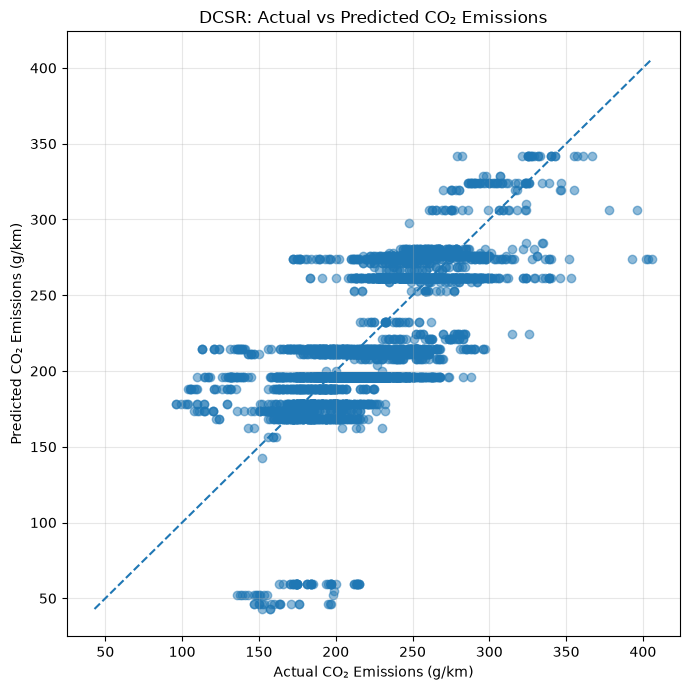

In [56]:
# ACTUAL VS PREDICTED

plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    y_test_np,
    y_test_pred,
    alpha=0.5
)

min_value = min(
    y_test_np.min(),
    y_test_pred.min()
)

max_value = max(
    y_test_np.max(),
    y_test_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual CO₂ Emissions (g/km)"
)

plt.ylabel(
    "Predicted CO₂ Emissions (g/km)"
)

plt.title(
    "DCSR: Actual vs Predicted CO₂ Emissions"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

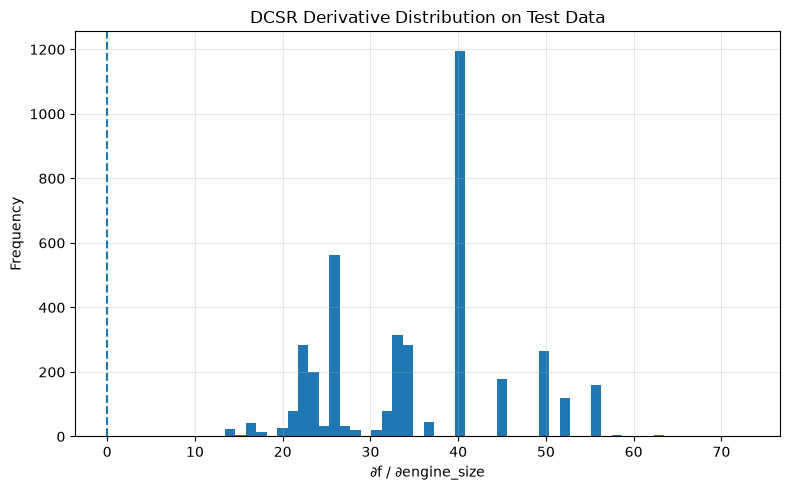

In [57]:
# DERIVATIVE DISTRIBUTION

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    test_derivative_valid,
    bins=50
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "∂f / ∂engine_size"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "DCSR Derivative Distribution on Test Data"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# SAVE DCSR RESULTS

os.makedirs(
    "../results/tables",
    exist_ok=True
)

os.makedirs(
    "../results/equations",
    exist_ok=True
)

os.makedirs(
    "../results/figures",
    exist_ok=True
)

results = pd.DataFrame(
    [{
        "Model": "DCSR",
        "TrainR2": train_r2,
        "TestR2": test_r2,
        "TrainMSE": train_mse,
        "TestMSE": test_mse,
        "TrainRMSE": train_rmse,
        "TestRMSE": test_rmse,
        "TrainMAE": train_mae,
        "TestMAE": test_mae,
        "TrainTime_s": train_time,
        "PredictTime_s": predict_time,
        "DCSR_Lambda": LAMBDA,
        "DCSR_Data_MSE": dcsr_model.best_e_data_,
        "DCSR_Physics_Penalty": dcsr_model.best_e_phys_,
        "Train_Derivative_Violation_Pct(pcvr)": train_violation_pct,
        "Test_Derivative_Violation_Pct(pcvr)": test_violation_pct,
        "Program_Length": dcsr_model.best_tree_.length(),
        "Program_Depth": dcsr_model.best_tree_.depth(),
        "Best_Generation": dcsr_model.best_generation_,
        "Train_PCVR_Pct": train_violation_pct,
        "Test_PCVR_Pct": test_violation_pct,

        # ---- CV SUMMARY METRICS ADDED HERE ----
        "CV_R2_Mean": cv_r2_mean,
        "CV_R2_Std": cv_r2_std,
        "CV_MSE_Mean": cv_mse_mean,
        "CV_MSE_Std": cv_mse_std,
        "CV_RMSE_Mean": cv_rmse_mean,
        "CV_RMSE_Std": cv_rmse_std,
        "CV_MAE_Mean": cv_mae_mean,
        "CV_MAE_Std": cv_mae_std,
        "CV_TrainTime_Mean_s": cv_train_time_mean,
        "CV_PredictTime_Mean_s": cv_predict_time_mean,
        "CV_Derivative_Violation_Mean_Pct": cv_violation_mean
    }]
)

results.to_csv(
    "../results/tables/dcsr_results.csv",
    index=False
)

# Save CV fold-level results
dcsr_cv_df.to_csv(
    "../results/tables/dcsr_5fold_cv_results.csv",
    index=False
)

with open(
    "../results/equations/dcsr_equation.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(
        equation
    )

history_df.to_csv(
    "../results/tables/dcsr_evolution_history.csv",
    index=False
)

print(
    "\nDCSR results saved successfully."
)


DCSR results saved successfully.
